# 03. Transformer — 용담댐 시간 유입량 예측 (입력세트 A / B / C)

**모델**: Transformer (`model: transformer`) — 주의(트랜스포머)
**한 줄 요약**: 자기주의(self-attention) 인코더. 720시간 창의 모든 시각 쌍을 직접 비교해 중요한 강우 시점을 가중.

이 노트북은 모델 비교 연구(10개 모델 × 3개 입력세트)의 **Transformer 부분**입니다. 모든 모델 노트북이 같은 구성을 가집니다.

1. 모델 설명 (논문 methodology용)
2. 자료와 실험 설정
3. 학습 (입력세트 A, B, C) 과 학습곡선
4. 학습 / 검증 / 테스트 기간 성능
5. 수문곡선 · 산점도 · 유량지속곡선
6. 홍수 첨두 재현
7. 결과 해석
8. 요약 (비교 노트북 `11_Comparison_Overall.ipynb`, `12_Comparison_Peaks.ipynb` 에서 사용하는 `results/transformer_<set>/` 생성)

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



## 1. 모델 설명 (Methodology)

**Transformer (encoder-only; NeuralHydrology `transformer`)**

순환 구조 대신 **자기주의(self-attention)** 로 시계열을 처리한다. 입력 $x_t$(강우)는 먼저 임베딩 네트워크(`dynamics_embedding`, 64차원)를
거치고, 위치 인코딩(sinusoidal, `sum`)이 더해진 뒤 $L$개의 인코더 층을 통과한다. 각 층은 다중 헤드 자기주의와 피드포워드 네트워크로 구성된다.

$$
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V, \qquad Q = XW_Q,\; K = XW_K,\; V = XW_V
$$

창의 마지막 시각에 대응하는 인코더 출력이 head를 거쳐 유입량이 된다. 순환 모델과 달리 720개 시각 전체가 한 번에 병렬 처리되며, 어떤 과거
시각이 현재 유입량에 기여하는지가 주의 가중치로 드러난다.

### 1.1 수문학적 관점에서의 특징

- 주의 메커니즘은 **창 안의 특정 강우 사상(예: 3일 전의 집중호우)** 을 거리와 무관하게 직접 참조할 수 있어 지체시간이 긴 유역에 유리하다.
- 반면 **누적·감수 같은 상태 전이**를 명시적으로 모델링하지 않고 위치 인코딩에 의존하므로, 데이터가 적을 때 저유량 구간이 불안정하거나
  LSTM보다 과적합되기 쉽다는 보고가 많다.
- 연산량이 시퀀스 길이의 제곱($720^2$)에 비례하므로 epoch당 학습 시간이 순환 모델보다 길다.

### 1.2 본 연구에서의 설정

| 항목 | 값 | 이유 |
|---|---|---|
| `dynamics_embedding` | fc, 64, tanh | 입력 차원을 헤드 수(4)로 나누어 떨어지는 64차원으로 올림 |
| `transformer_nheads` / `nlayers` | 4 / 2 | 작은 데이터에 맞춘 얕은 인코더 |
| `transformer_dim_feedforward` | 128 | 은닉 64의 2배 |
| `transformer_dropout` / `positional_dropout` | 0.1 / 0.1 | 표준값 |
| `transformer_positional_encoding_type` | sum | 임베딩에 위치 인코딩을 더함 |

### 참고문헌

- Vaswani, A. et al. (2017). Attention is all you need. *NeurIPS*.
- Kratzert, F. et al. (2022). NeuralHydrology (transformer 구현). *JOSS*.


## 2. 자료와 실험 설정

`common.py` 가 run 디렉터리 탐색, 평가, 그림을 모두 담당하므로 노트북 코드는 짧습니다. 아래 셀은 공통 설정을 불러오고 그림 스타일(큰 글꼴,
300 dpi 저장)을 지정합니다.

In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

MODEL = "transformer"
NAME = MODEL_NAME[MODEL]
print(NAME, "->", common.MODEL_SPECS[MODEL]["nh_model"])

Transformer -> transformer


### 2.1 자료 개요

연도별 유역평균 강수량과 유입량(평균·최대)입니다. 음영은 학습(회색) / 검증(주황) / 테스트(녹색) 기간입니다.
테스트 기간(2022–2025)에는 2023년과 2024년의 큰 홍수가 포함되어 있고, 학습 기간에는 2020년(최대 4,395 m³/s)이 **포함되지 않는다**는 점에 유의합니다
(2020년은 검증 기간). 즉 모델은 학습에서 본 적 없는 크기의 홍수를 검증·테스트에서 재현해야 하며, 이것이 모델 간 외삽 능력 차이를 드러냅니다.

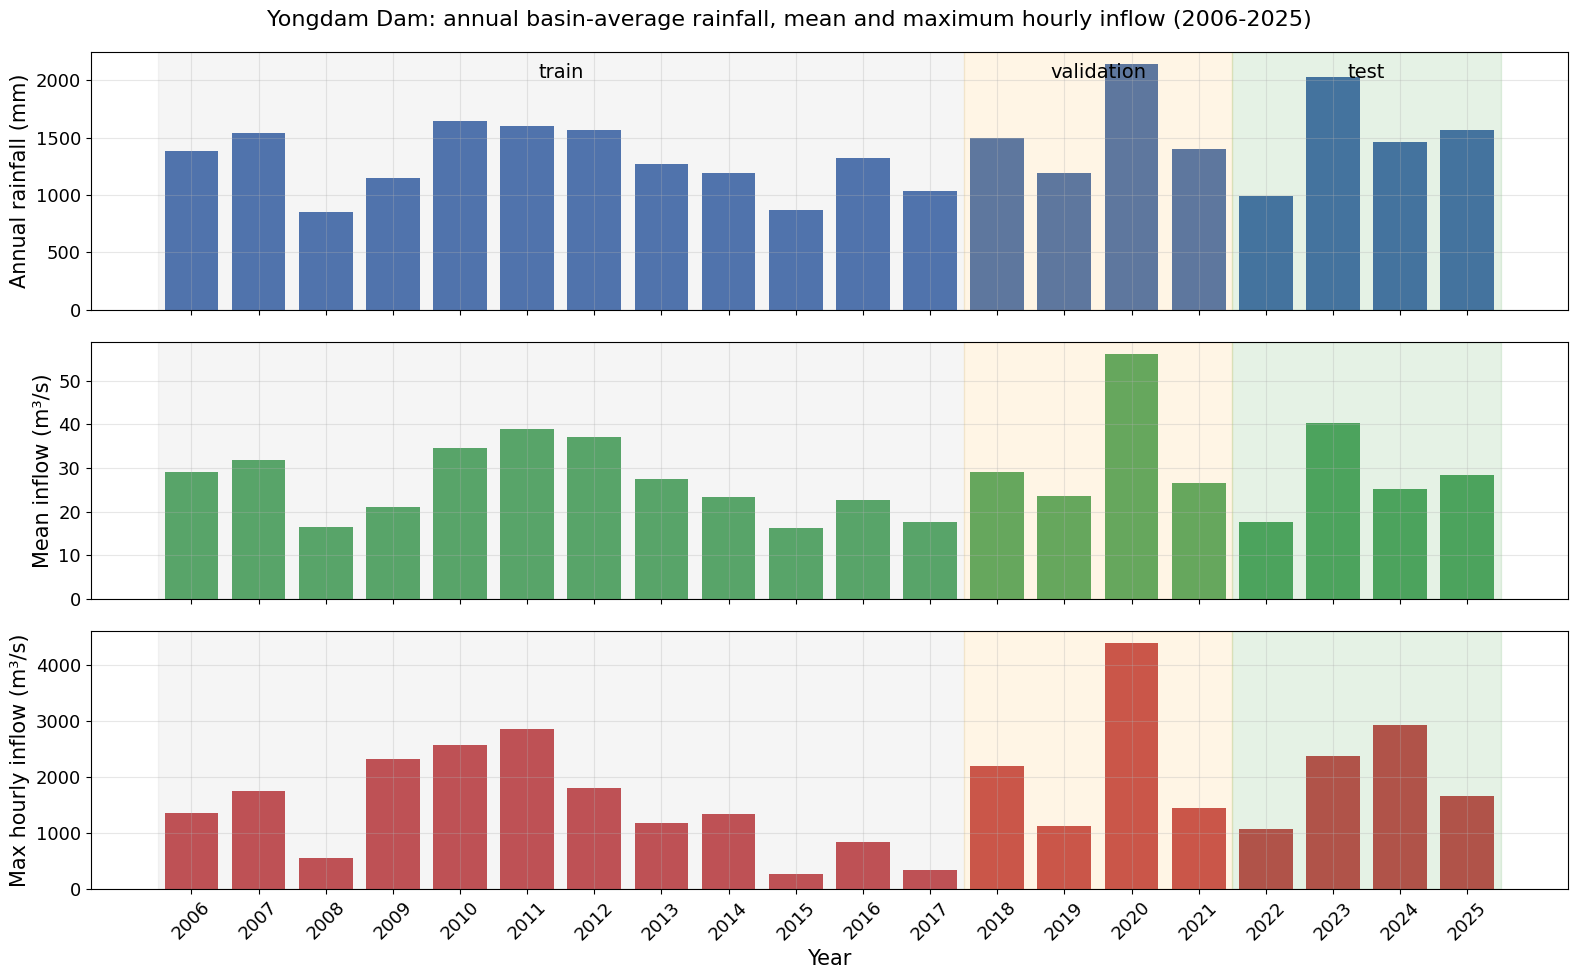

In [2]:
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
inflow = common.load_observed_inflow()
annual = pd.DataFrame({"rain_mm": rain.resample("YE").sum(), "inflow_mean": inflow.resample("YE").mean(),
                       "inflow_max": inflow.resample("YE").max()})
annual.index = annual.index.year
annual = annual.loc[2006:2025]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
axes[0].bar(annual.index, annual["rain_mm"], color="#4c72b0")
axes[0].set_ylabel("Annual rainfall (mm)")
axes[1].bar(annual.index, annual["inflow_mean"], color="#55a868")
axes[1].set_ylabel("Mean inflow (m³/s)")
axes[2].bar(annual.index, annual["inflow_max"], color="#c44e52")
axes[2].set_ylabel("Max hourly inflow (m³/s)")
for ax in axes:
    ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2011.5, axes[0].get_ylim()[1] * 0.9, "train", ha="center", fontsize=14)
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "validation", ha="center", fontsize=14)
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test", ha="center", fontsize=14)
axes[2].set_xlabel("Year")
axes[2].set_xticks(annual.index)
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Yongdam Dam: annual basin-average rainfall, mean and maximum hourly inflow (2006-2025)", fontsize=16)
fig.tight_layout()
plt.show()


### 2.2 입력세트별 설정 파일

세 입력세트의 설정은 `dynamic_inputs` (와 모델에 따라 그에 연동된 몇 개 키)만 다릅니다. 아래 표는 공통 설정과 다른 항목만 보여 줍니다.
전체 파일은 `configs/transformer_<set>.yml` 입니다.

In [3]:
rows = {}
for s in SETS:
    rows[f"Set {s}"] = {k: str(v) for k, v in common.model_specific_config(MODEL, s).items()}
cfg_table = pd.DataFrame(rows).fillna("")
display(cfg_table)
print(Path(common.config_path(MODEL, "A")).read_text())

,Set A,Set B,Set C
experiment_name,transformer_A,transformer_B,transformer_C
model,transformer,transformer,transformer
dynamics_embedding,"{'type': 'fc', 'hiddens': [64], 'activation': ...","{'type': 'fc', 'hiddens': [64], 'activation': ...","{'type': 'fc', 'hiddens': [64], 'activation': ..."
transformer_nheads,4,4,4
transformer_nlayers,2,2,2
transformer_dim_feedforward,128,128,128
transformer_dropout,0.1,0.1,0.1
transformer_positional_dropout,0.1,0.1,0.1
transformer_positional_encoding_type,sum,sum,sum
output_dropout,0.4,0.4,0.4


experiment_name: transformer_A
run_dir: null
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt
train_start_date: 01/01/2006
train_end_date: 31/12/2017
validation_start_date: 01/01/2018
validation_end_date: 31/12/2021
test_start_date: 01/01/2022
test_end_date: 31/12/2025
seed: 111
device: cuda:0
validate_every: 1
validate_n_random_basins: 1
metrics:
- NSE
- KGE
head: regression
output_activation: linear
optimizer: Adam
loss: MSE
learning_rate:
  0: 0.001
batch_size: 256
epochs: 50
clip_gradient_norm: 1
early_stopping: true
patience_early_stopping: 5
minimum_epochs_before_early_stopping: 30
patience_dynamic_learning_rate: 3
factor_dynamic_learning_rate: 0.5
seq_length: 720
predict_last_n: 1
num_workers: 4
log_interval: 100
log_tensorboard: false
log_n_figures: 0
save_weights_every: 1
save_validation_results: false
dataset: hourlycsv
data_dir: ../../data/YDDam_paper
forcings:
- hourly
target_variables:
- inflow
clip_targets_to_zero:


## 3. 학습

`common.train()` 은 완료된 run (`runs/transformer_<set>_<날짜>_<시각>/`) 이 있으면 학습을 건너뛰고, 없으면 `nh-run train` 을 서브프로세스로
실행합니다 (`train_all.py` 로 미리 학습해 두어도 같은 run 을 사용합니다). 이어서 `common.evaluate_run()` 이

1. `output.log` 에서 epoch별 학습/검증 loss 와 검증 NSE/KGE 를 읽고,
2. 검증 loss 최소 epoch 을 골라 학습·검증·테스트 기간을 평가(`nh-run evaluate`)하고,
3. 시간 단위 예측을 m³/s 로 통일해 지표를 계산한 뒤 `results/transformer_<set>/` 에 저장합니다.

In [4]:
summaries, histories, preds = {}, {}, {}
for s in SETS:
    run_dir = common.train(MODEL, s, in_process=False)
    summaries[s] = common.evaluate_run(MODEL, s, run_dir)
    histories[s] = common.load_saved_history(MODEL, s)
    preds[s] = common.load_saved_predictions(MODEL, s)
    print(f"Set {s}: run={summaries[s]['run_dir']}  epochs={summaries[s]['epochs_trained']}  best={summaries[s]['best_epoch']}  "
          f"params={summaries[s]['n_parameters']:,}  {summaries[s]['epoch_time_mean_s']:.0f} s/epoch")

[transformer_A] completed run found, skipping training: transformer_A_2010_115307
Set A: run=transformer_A_2010_115307  epochs=48  best=43  params=67,137  113 s/epoch
[transformer_B] completed run found, skipping training: transformer_B_2010_120204
Set B: run=transformer_B_2010_120204  epochs=36  best=4  params=67,521  126 s/epoch
[transformer_C] completed run found, skipping training: transformer_C_2010_120312


Set C: run=transformer_C_2010_120312  epochs=45  best=5  params=67,585  114 s/epoch


### 3.1 학습곡선

왼쪽: 학습 loss(표준화된 MSE), 가운데: 검증 loss, 오른쪽: 검증 기간(2018–2021) NSE. 점선은 검증 loss 최소 epoch(평가에 쓴 체크포인트)입니다.
early stopping 은 30 epoch 이후 검증 loss 가 5 epoch 연속 개선되지 않으면 학습을 멈춥니다.

- 학습 loss 가 계속 내려가는데 검증 loss 가 올라가면 **과적합**, 둘 다 높은 채 머물면 **표현력 부족 또는 학습률 문제**입니다.
- 검증 NSE 가 들쭉날쭉하면 2020년 대홍수(검증 기간) 재현이 epoch 마다 흔들린다는 뜻입니다.

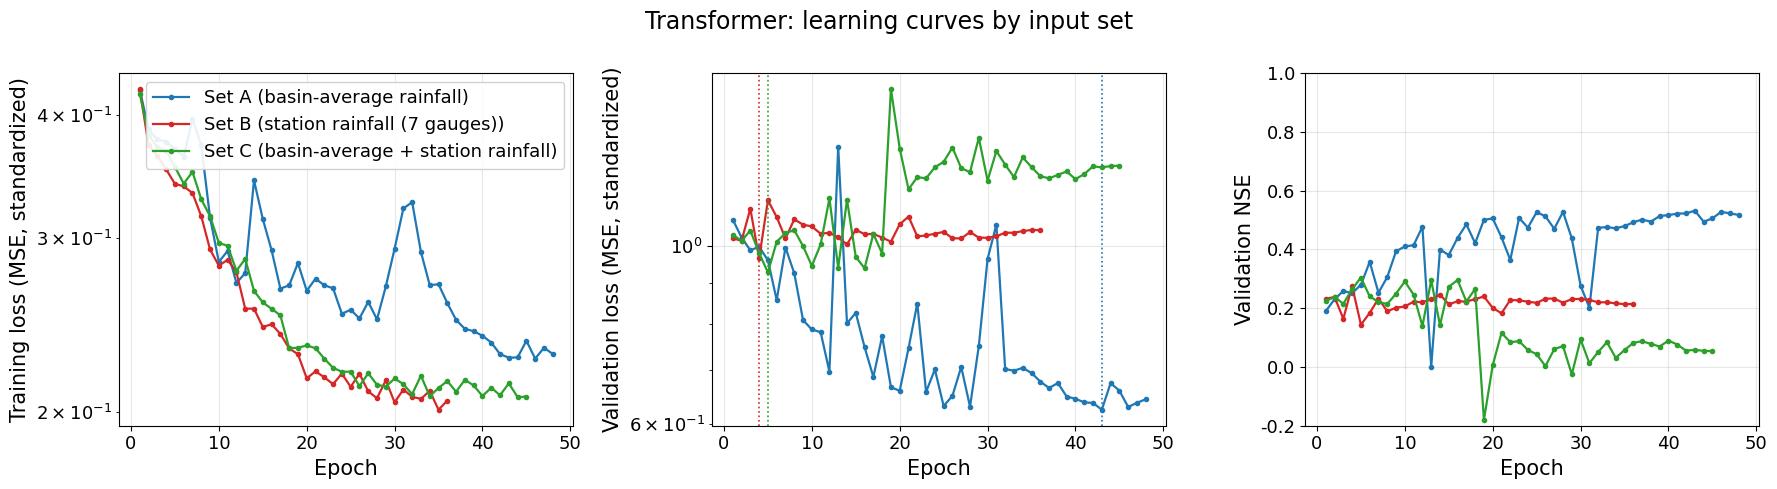

In [5]:
fig = common.plot_learning_curves(histories, title=f"{NAME}: learning curves by input set",
                                  labels={s: f"Set {s} ({common.INPUT_SET_NAMES[s]})" for s in SETS},
                                  colors=SET_COLOR, styles={s: "-" for s in SETS},
                                  best_epochs={s: summaries[s]["best_epoch"] for s in SETS})
common.save_fig(fig, f"{MODEL}_learning_curves")
plt.show()

## 4. 학습 / 검증 / 테스트 기간 성능

모든 지표는 **시간 단위, m³/s** 로 계산합니다 (MC-LSTM 의 mm/h 예측도 변환). 지표의 의미:

| 지표 | 의미 | 이상값 |
|---|---|---|
| NSE | 관측 평균 대비 설명력. 제곱오차 기반이라 **홍수(고유량)** 에 민감 | 1 |
| KGE | 상관(r)·변동성비(α)·편향비(β)를 함께 보는 지표 | 1 |
| RMSE / MAE | 오차의 크기 (m³/s) | 0 |
| PBIAS | 총량 편향(%) (+ 과대, − 과소) | 0 |
| Alpha-NSE / Beta-NSE | 표준편차 비 / 평균 편향(관측 표준편차로 정규화) | 1 / 0 |
| FHV / FMS / FLV | 유량지속곡선의 고유량(상위 2%) / 중간 구간 기울기 / 저유량(하위 30%) 편향(%) | 0 |
| Peak-Timing | 관측 첨두(자동 탐지)의 시각 오차 평균(h) | 0 |
| Peak-MAPE | 자동 탐지된 모든 첨두의 평균 절대 백분율 오차(%) | 0 |
| Missed-Peaks | 자동 탐지 첨두 중 예측이 놓친 비율 | 0 |

(첨두 자동 탐지는 라이브러리 기본 규칙으로 작은 첨두까지 포함하므로 값이 큽니다. 큰 홍수사건에 대한 분석은 6절과 `" + NB_PEAKS + "` 참고.)

In [6]:
rows = []
for s in SETS:
    for p in PERIODS:
        rows.append({"set": s, "period": p, **summaries[s]["metrics"][p]})
metrics_long = pd.DataFrame(rows).set_index(["set", "period"])[common.MAIN_METRICS]
display(metrics_long.round(3))
metrics_long.to_csv(common.RESULTS_DIR / f"{MODEL}_metrics_by_period.csv")

NSE    KGE    RMSE     MAE   PBIAS  Pearson-r  Alpha-NSE  Beta-NSE     FHV     FMS     FLV  Peak-Timing  Peak-MAPE  Missed-Peaks
set period                                                                                                                                        
A   train       0.596  0.556  45.679  14.261 -21.377      0.784      0.676    -0.079 -22.584 -42.884  98.300        4.703     76.787         0.612
    validation  0.532  0.527  80.099  19.470 -17.818      0.736      0.651    -0.052 -18.329 -26.052  98.821        2.244     63.320         0.670
    test        0.559  0.715  57.509  17.048  -2.343      0.755      0.857    -0.008   0.003 -57.558  97.827        3.654     63.731         0.658
B   train       0.385  0.323  56.767  23.471  41.184      0.640      0.601     0.151 -24.134 -36.618  95.710        4.815     64.747         0.601
    validation  0.275  0.207  99.616  30.609  20.911      0.560      0.375     0.061 -53.010 -15.505  97.116        3.366     74.374         0.649
    test        0.169  0.104  78.984  29.807  43.533      0.435      0.458     0.140 -44.940 -54.849  95.385        2.981     68.797         0.596
C   train       0.386  0.335  56.687  17.099 -27.709      0.644      0.512    -0.102 -39.076   1.571  93.087        4.421     81.072         0.610
    validation  0.304  0.224  97.617  23.509 -25.285      0.592      0.390    -0.073 -52.118  25.518  94.197        2.634     81.891         0.664
    test        0.222  0.179  76.442  20.760 -23.559      0.483      0.407    -0.076 -53.148 -37.877  89.000        3.346     77.160         0.615

### 4.1 기간별 NSE · KGE · PBIAS 비교

학습 기간 대비 검증·테스트 기간의 하락 폭이 **일반화 성능**을 보여 줍니다. 입력세트 간 차이는 관측소별 강우(B, C)가 유역평균(A)보다
추가 정보를 주는지를 말해 줍니다.

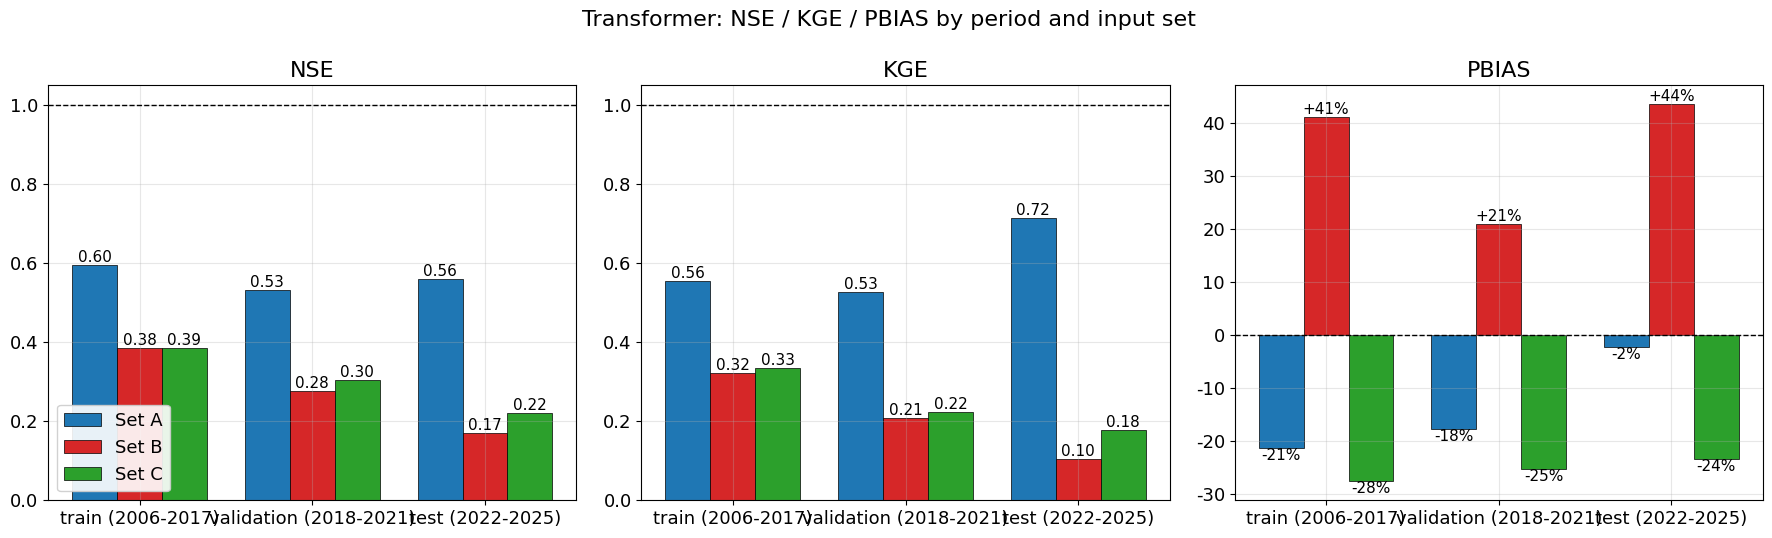

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, metric in zip(axes, ["NSE", "KGE", "PBIAS"]):
    x = np.arange(len(PERIODS))
    w = 0.26
    for i, s in enumerate(SETS):
        vals = [summaries[s]["metrics"][p][metric] for p in PERIODS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if metric != "PBIAS" else f"{v:+.0f}%",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([PERIOD_LABEL[p] for p in PERIODS])
    ax.set_title(metric)
    ax.axhline(common.METRIC_IDEAL[metric], color="black", ls="--", lw=1)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.5, min(0, ax.get_ylim()[0])), 1.05)
axes[0].legend(loc="lower left")
fig.suptitle(f"{NAME}: NSE / KGE / PBIAS by period and input set", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_metrics_by_period")
plt.show()

### 4.2 관측 vs 예측 산점도 (로그축)

행 = 기간, 열 = 입력세트. 로그축이므로 저유량(수 m³/s)과 홍수(수천 m³/s)의 거동을 한 그림에서 볼 수 있습니다.
1:1 선 아래로 휘면 고유량 과소, 왼쪽 위로 퍼지면 저유량 과대입니다. 관측값 0 (전체의 약 16%) 은 0.1 로 잘라 표시합니다.

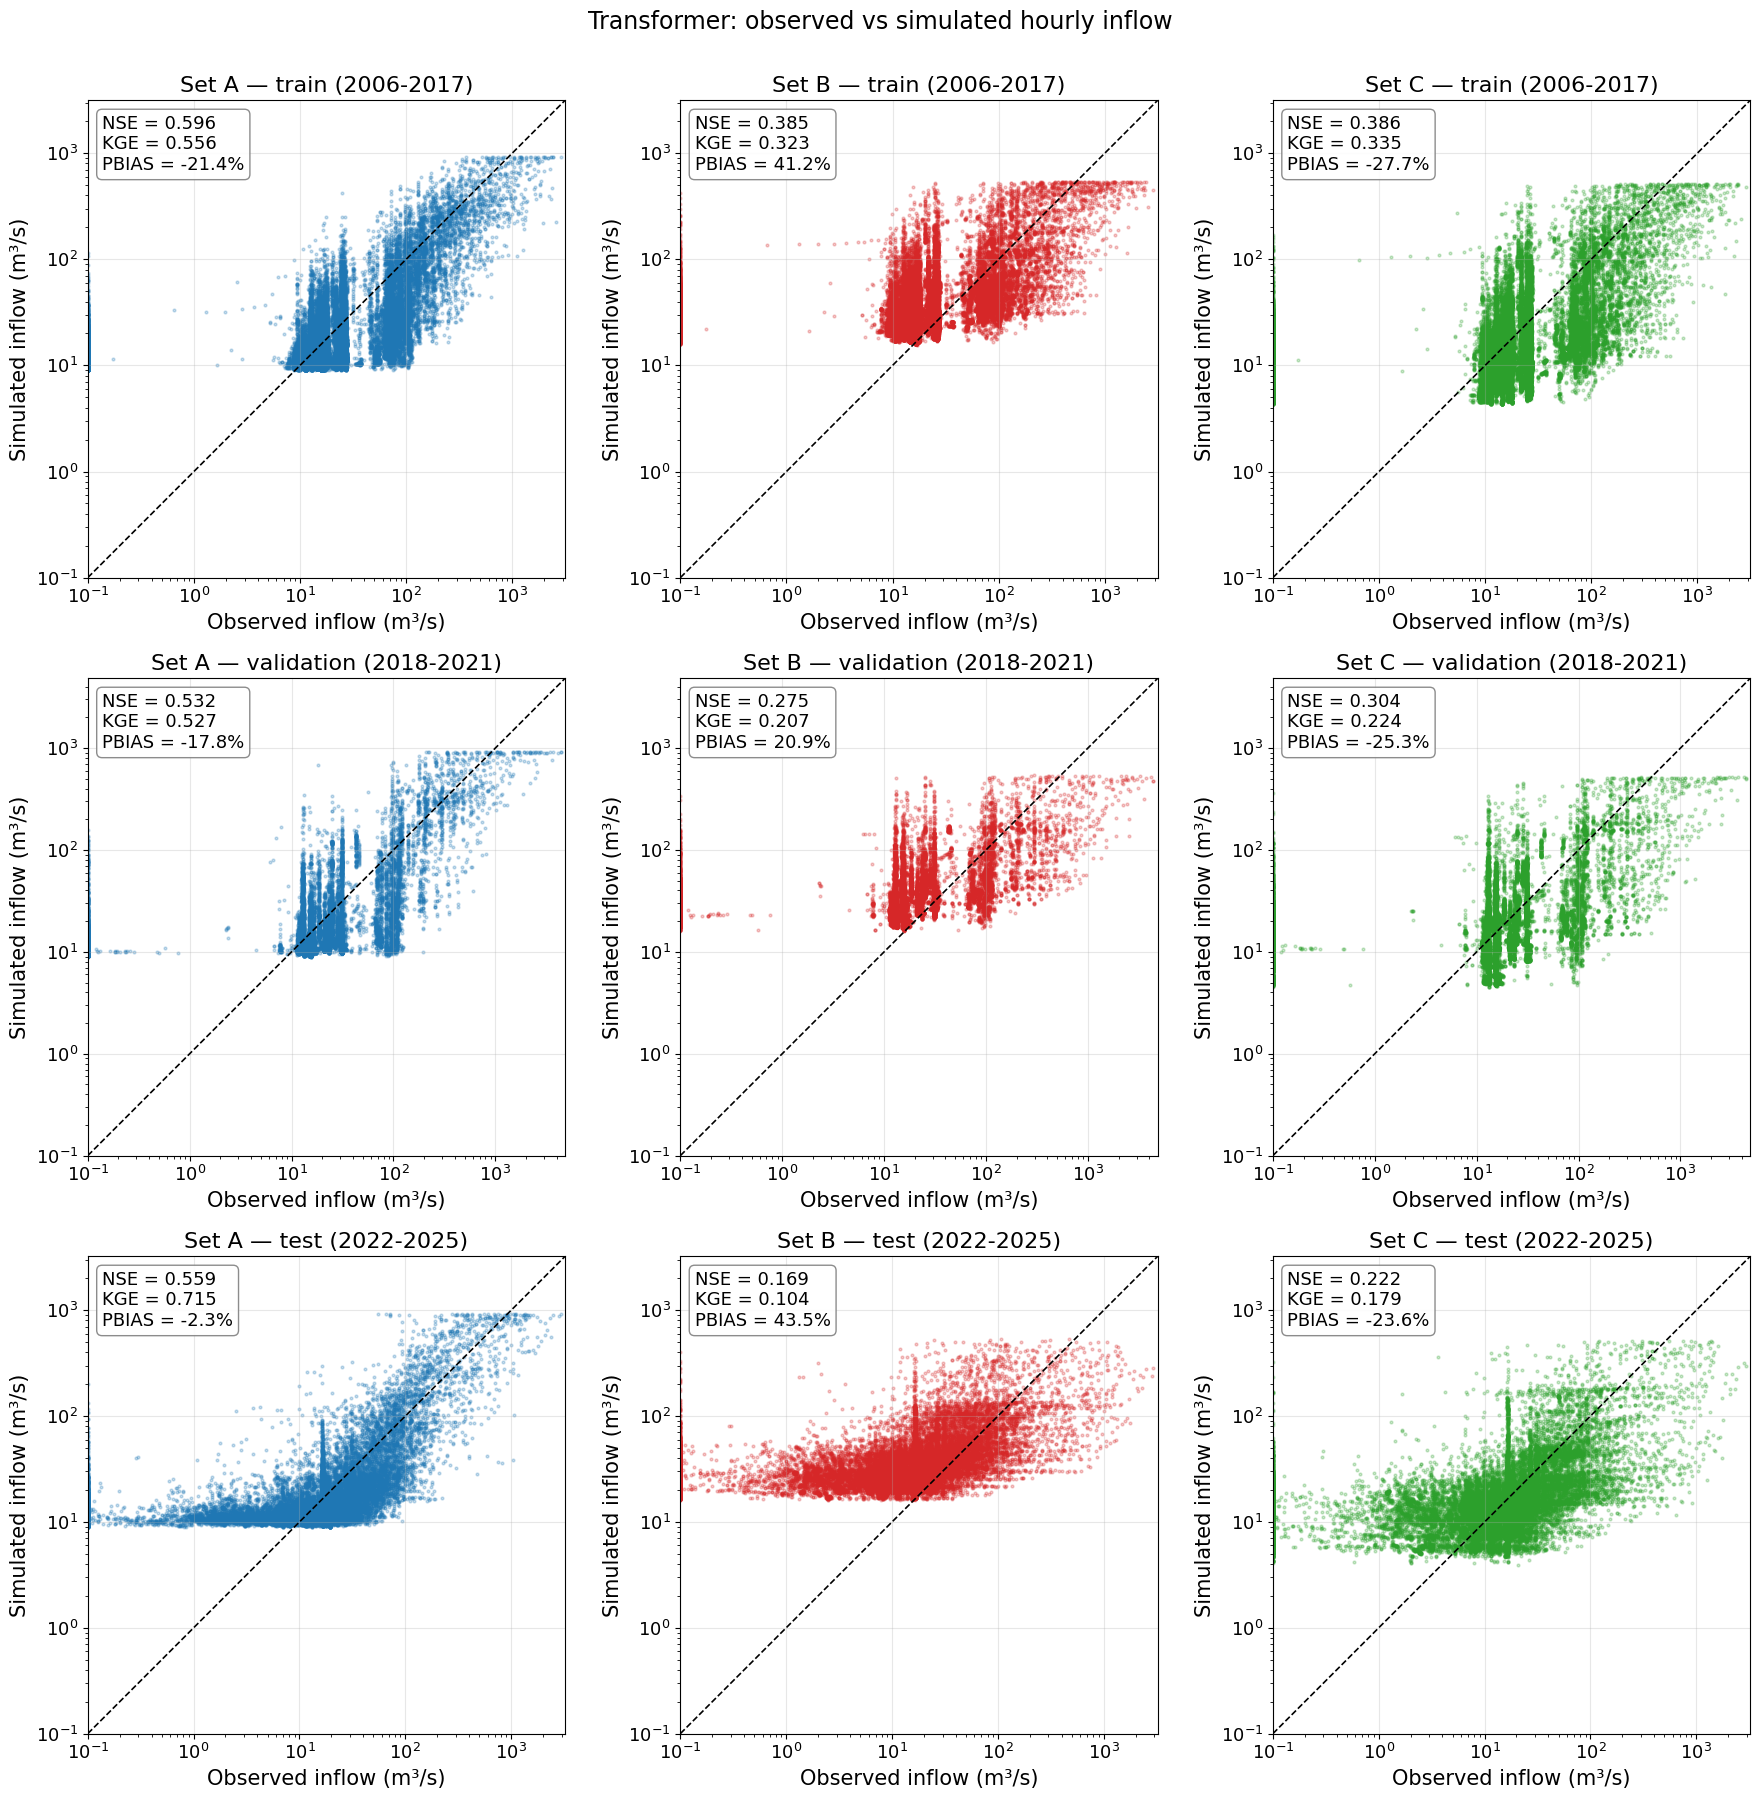

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, p in enumerate(PERIODS):
    for j, s in enumerate(SETS):
        df = preds[s][preds[s]["period"] == p]
        common.plot_scatter(df["obs"], df["sim"], title=f"Set {s} — {PERIOD_LABEL[p]}", ax=axes[i, j], color=SET_COLOR[s])
fig.suptitle(f"{NAME}: observed vs simulated hourly inflow", fontsize=17, y=1.0)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_scatter")
plt.show()

## 5. 수문곡선 · 유량지속곡선

### 5.1 테스트 기간(2022–2025) 연도별 수문곡선

각 패널은 한 해의 시간 유입량입니다. 검은 선 = 관측, 색 선 = 입력세트별 예측, 위쪽 막대 = 유역평균 강우(역축).
홍수기(6–9월)의 첨두 크기와 상승·하강 시점, 건기의 저유량 수준을 봅니다.

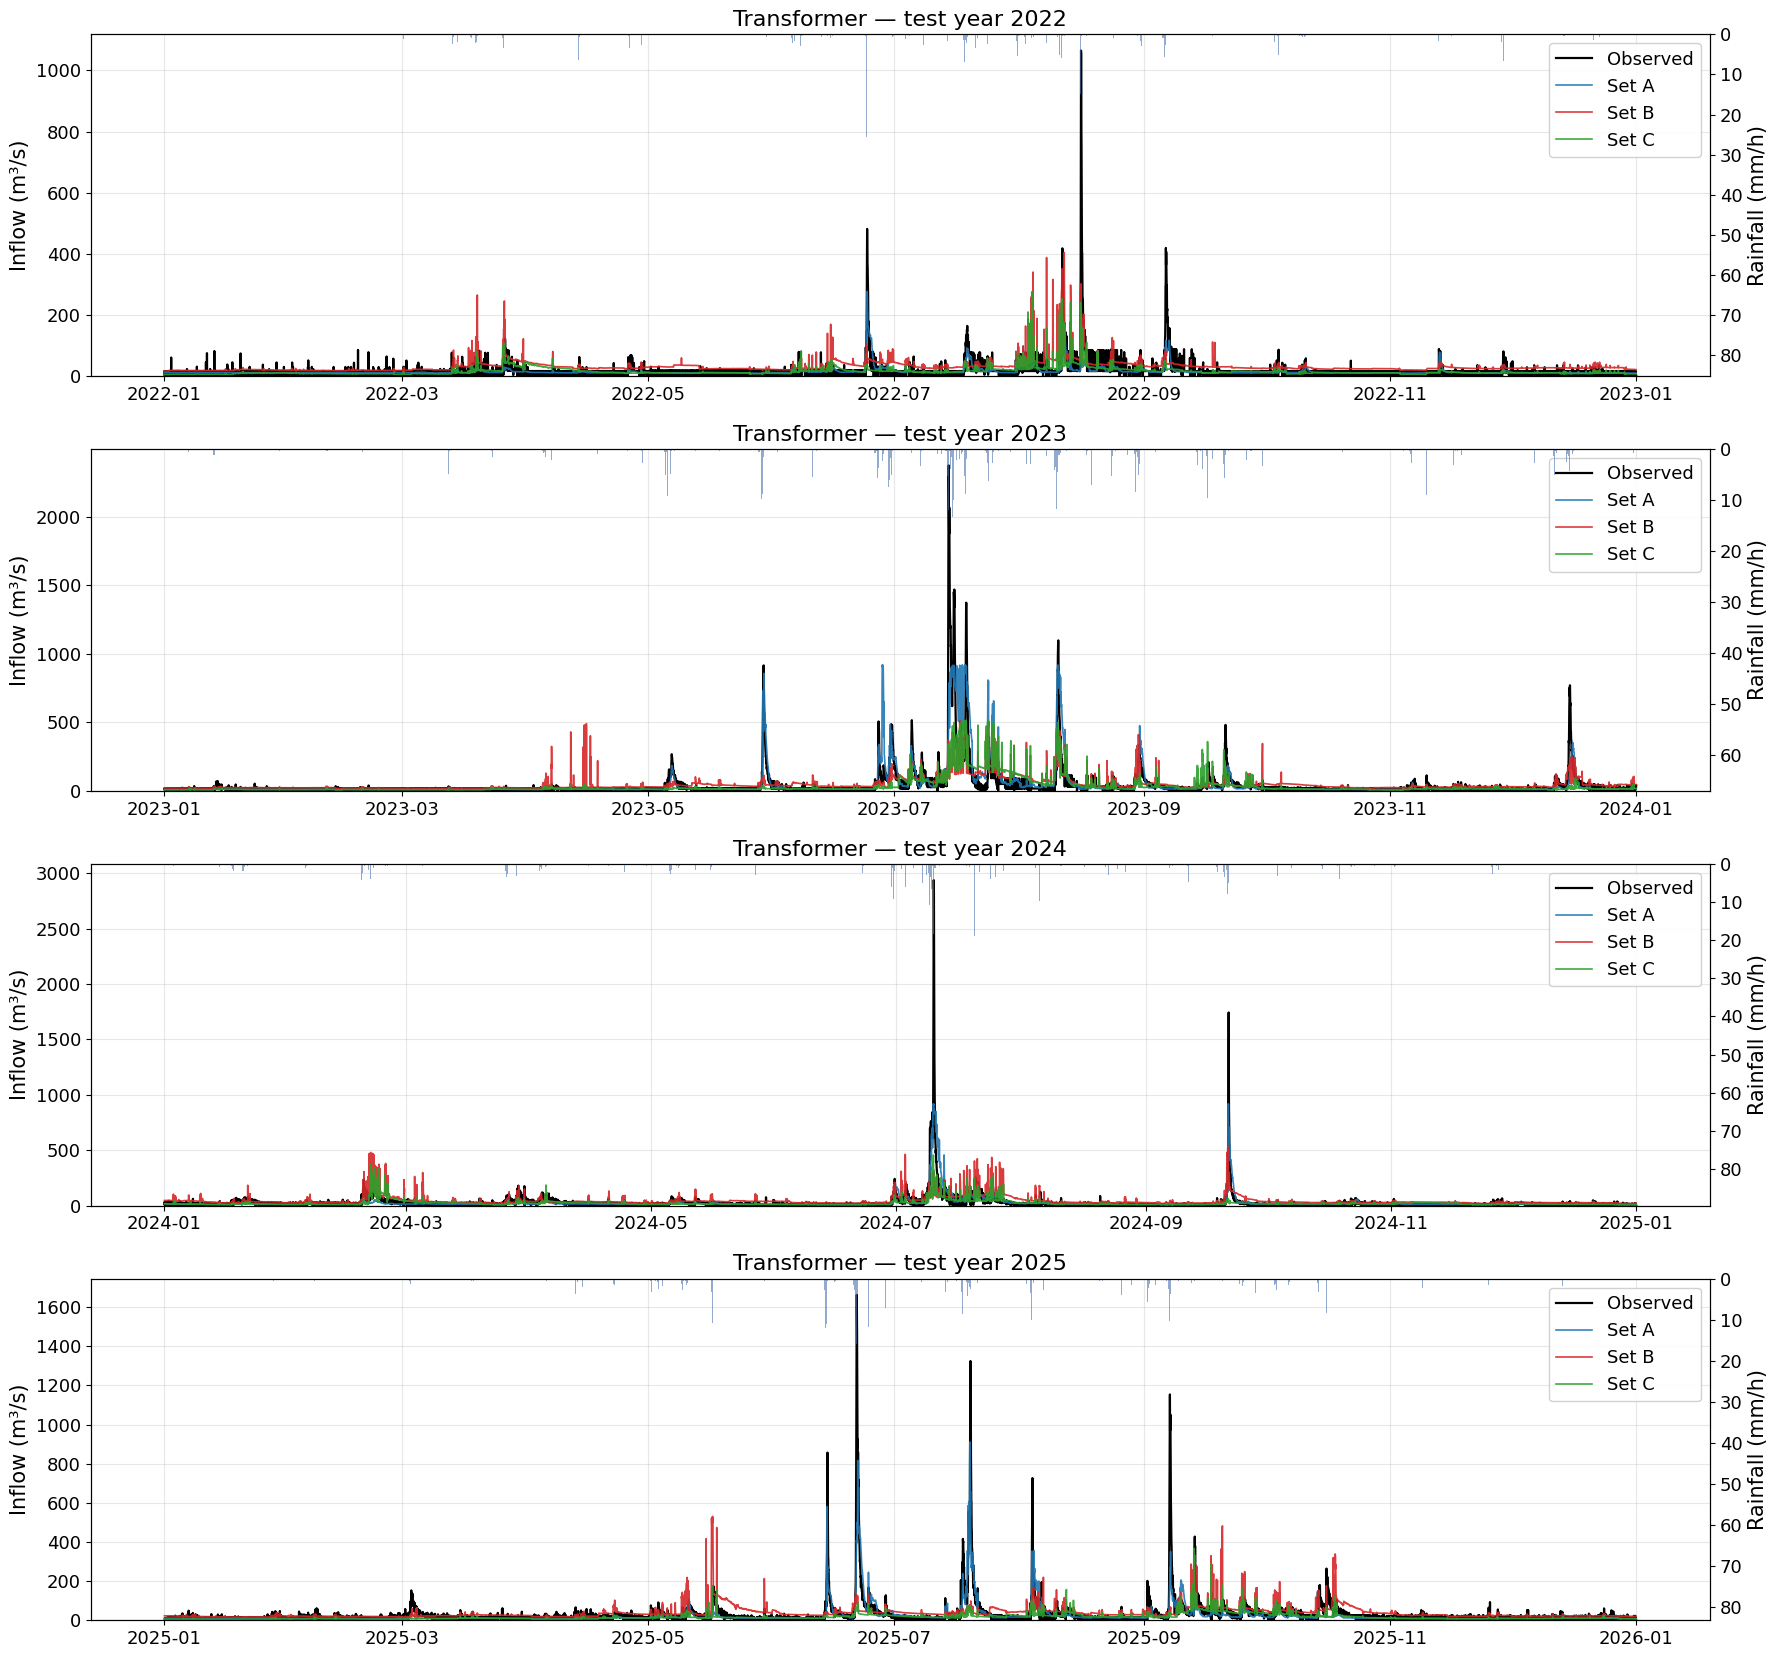

In [9]:
test_years = range(2022, 2026)
fig, axes = plt.subplots(len(test_years), 1, figsize=(18, 4.2 * len(test_years)))
for ax, year in zip(axes, test_years):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    obs = preds["A"].loc[start:end, "obs"]
    common.plot_hydrograph(obs, {f"Set {s}": preds[s].loc[start:end, "sim"] for s in SETS}, rain=rain.loc[start:end],
                           title=f"{NAME} — test year {year}", ax=ax, colors={f"Set {s}": SET_COLOR[s] for s in SETS},
                           styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.2, obs_lw=1.6)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_hydrograph_test")
plt.show()

### 5.2 테스트 기간 최대 홍수사건 3개 확대

관측 첨두가 가장 큰 세 사건을 전후 5일 범위로 확대합니다. 시간 해상도이므로 첨두 **시각**까지 비교할 수 있습니다.

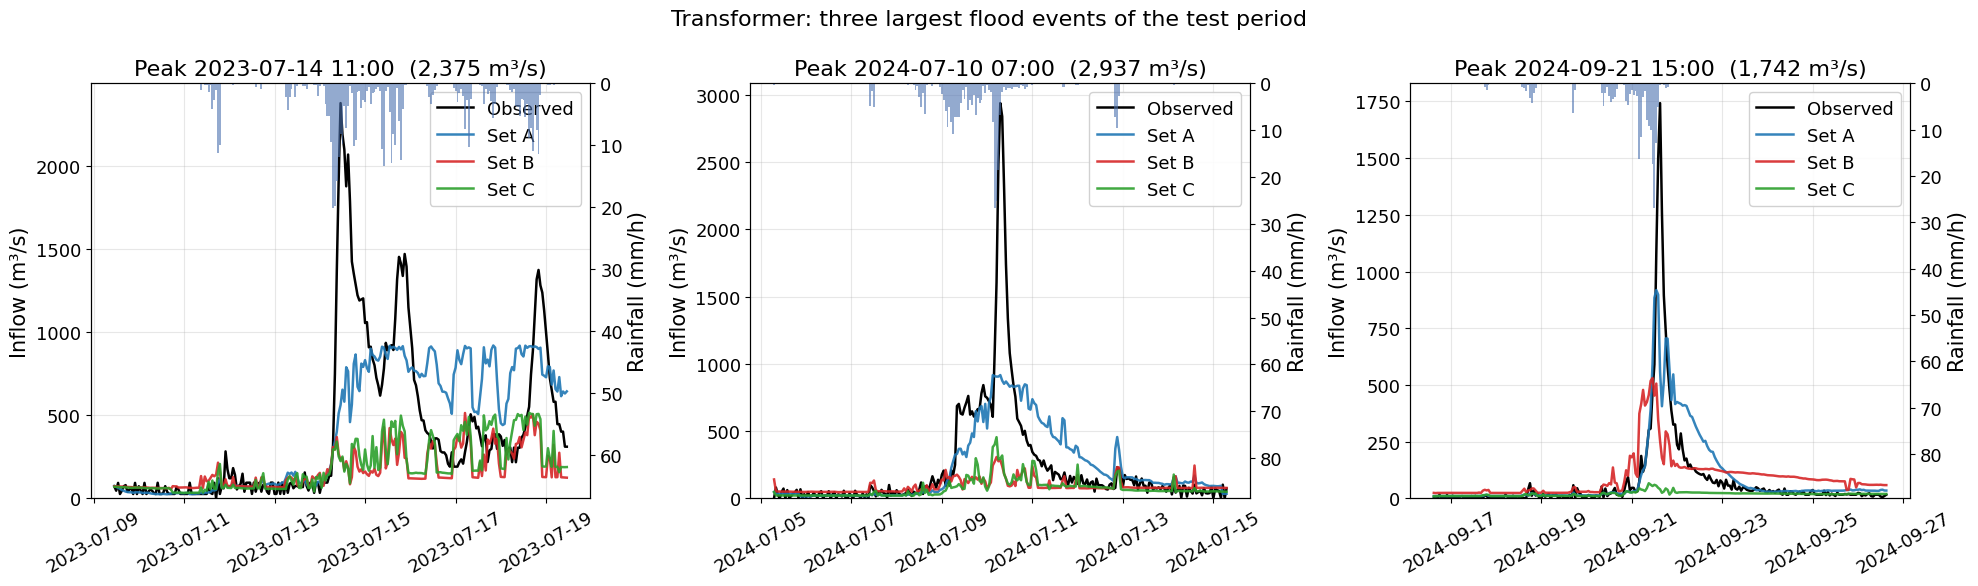

In [10]:
test_obs = preds["A"].loc[preds["A"]["period"] == "test", "obs"]
events = common.detect_events(test_obs, n_events=15)
top3 = sorted(events, key=lambda t: test_obs[t], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, peak in zip(axes, sorted(top3)):
    start, end = peak - pd.Timedelta(days=5), peak + pd.Timedelta(days=5)
    common.plot_hydrograph(preds["A"]["obs"], {f"Set {s}": preds[s]["sim"] for s in SETS}, rain=rain, start=start, end=end,
                           title=f"Peak {peak:%Y-%m-%d %H:00}  ({test_obs[peak]:,.0f} m³/s)", ax=ax,
                           colors={f"Set {s}": SET_COLOR[s] for s in SETS}, styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NAME}: three largest flood events of the test period", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_events_top3")
plt.show()

### 5.3 유량지속곡선 (테스트 기간)

고유량(FHV, 왼쪽 음영)과 저유량(FLV, 오른쪽 음영) 구간에서 관측 곡선과의 간격이 각각 FHV, FLV 지표에 해당합니다.

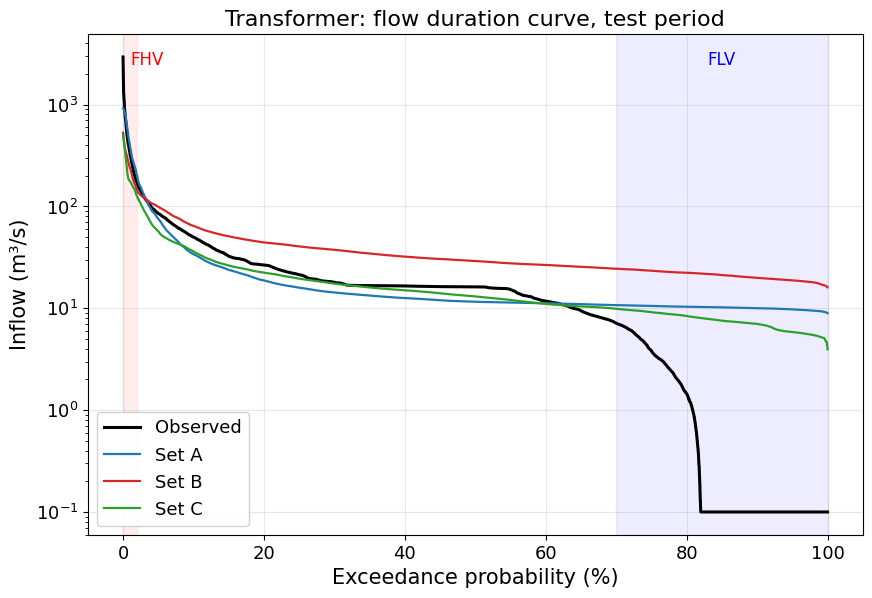

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
common.plot_fdc(test_obs, {f"Set {s}": preds[s].loc[preds[s]["period"] == "test", "sim"] for s in SETS},
                title=f"{NAME}: flow duration curve, test period", colors={f"Set {s}": SET_COLOR[s] for s in SETS}, ax=ax)
common.save_fig(fig, f"{MODEL}_fdc_test")
plt.show()

### 5.4 연도별 NSE

20년 전체를 연도별로 나눠 본 NSE 입니다. 배경 음영은 학습/검증/테스트 기간. 특정 해의 성능 급락은 보통 그 해의 큰 홍수를 놓쳤음을 뜻합니다.

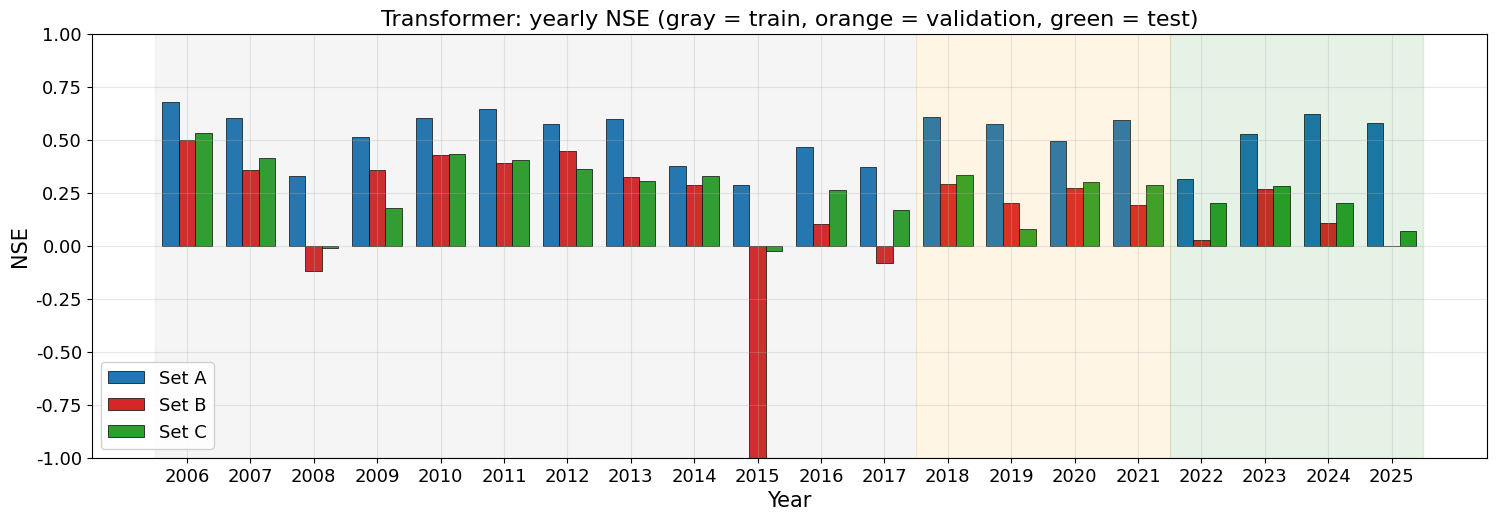

A             B             C       
        NSE    KGE    NSE    KGE    NSE    KGE
year                                          
2006  0.679  0.810  0.502  0.438  0.532  0.505
2007  0.605  0.546  0.358  0.413  0.417  0.476
2008  0.331  0.266 -0.117 -0.143 -0.010 -0.159
2009  0.516  0.444  0.359  0.135  0.178  0.033
2010  0.603  0.485  0.431  0.388  0.436  0.332
2011  0.648  0.575  0.390  0.371  0.404  0.340
2012  0.578  0.441  0.450  0.444  0.364  0.296
2013  0.598  0.566  0.328  0.312  0.309  0.275
2014  0.376  0.362  0.286  0.261  0.328  0.343
2015  0.288  0.438 -1.685 -0.298 -0.026  0.084
2016  0.467  0.610  0.104  0.064  0.266  0.204
2017  0.373  0.326 -0.079  0.056  0.169  0.212
2018  0.610  0.760  0.293  0.219  0.335  0.359
2019  0.575  0.499  0.204  0.131  0.081 -0.025
2020  0.496  0.453  0.272  0.204  0.301  0.189
2021  0.597  0.548  0.193  0.145  0.286  0.197
2022  0.318  0.262  0.026 -0.034  0.202  0.193
2023  0.530  0.735  0.271  0.243  0.282  0.286
2024  0.622  0.664  0.106 -0.073  0.203  0.121
2025  0.582  0.540 -0.002 -0.021  0.071 -0.115

In [12]:
yearly = {s: common.yearly_metrics(preds[s]) for s in SETS}
fig, ax = plt.subplots(figsize=(18, 5.5))
years = yearly["A"].index
w = 0.26
for i, s in enumerate(SETS):
    ax.bar(years + (i - 1) * w, yearly[s]["NSE"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
ax.set_ylim(max(-1, min(0, np.nanmin([yearly[s]["NSE"].min() for s in SETS]) - 0.05)), 1.0)
ax.set_xticks(years)
ax.set_ylabel("NSE")
ax.set_xlabel("Year")
ax.set_title(f"{NAME}: yearly NSE (gray = train, orange = validation, green = test)")
ax.legend(loc="lower left")
common.save_fig(fig, f"{MODEL}_yearly_nse")
plt.show()
display(pd.concat({s: yearly[s][["NSE", "KGE"]] for s in SETS}, axis=1).round(3))

## 6. 홍수 첨두 재현 (테스트 기간 상위 15개 사건)

관측 첨두를 서로 72시간 이상 떨어지도록 골라 독립 사건 15개를 정의하고, 사건마다

- **첨두 크기 오차** = (예측 첨두 − 관측 첨두) / 관측 첨두 × 100 (%) — 예측 첨두는 관측 첨두 ±24 h 안의 최대값
- **첨두 시각 오차** = 예측 첨두 시각 − 관측 첨두 시각 (h, + 는 지연)
- **사건 체적 오차** = 첨두 전 48 h ~ 후 96 h 구간 총량의 상대오차 (%)
- **사건 NSE** = 같은 구간의 NSE

를 계산합니다. 댐 운영에서는 평균적 적합도(NSE)보다 이 값들이 직접적인 관심사입니다.

In [13]:
event_tables = {s: common.load_saved_events(MODEL, s) for s in SETS}
best_set = max(SETS, key=lambda s: summaries[s]["metrics"]["test"]["NSE"])
print(f"테스트 NSE 가 가장 높은 입력세트: {best_set}")
t = event_tables[best_set].copy()
t[t.select_dtypes("number").columns] = t.select_dtypes("number").round(1)
display(t)
display(pd.DataFrame({s: summaries[s]["events_test"] for s in SETS}).round(2))

테스트 NSE 가 가장 높은 입력세트: A


,obs_peak,sim_peak,sim_peak_time,peak_error_pct,timing_error_h,volume_error_pct,event_NSE
obs_peak_time,,,,,,,
2022-08-16 07:00:00,1064.7,117.6,2022-08-16 06:00:00,-89.0,-1.0,-72.6,-0.1
2023-05-29 14:00:00,915.1,856.8,2023-05-29 16:00:00,-6.4,2.0,3.4,0.8
2023-06-27 02:00:00,506.0,918.8,2023-06-28 00:00:00,81.6,22.0,47.5,-1.8
2023-07-05 08:00:00,515.2,329.1,2023-07-05 05:00:00,-36.1,-3.0,-21.8,0.6
2023-07-14 11:00:00,2375.1,911.7,2023-07-15 09:00:00,-61.6,22.0,7.1,0.2
2023-07-18 20:00:00,1372.7,919.0,2023-07-17 20:00:00,-33.1,-24.0,72.4,-0.1
2023-08-10 16:00:00,1097.7,917.8,2023-08-10 14:00:00,-16.4,-2.0,57.7,0.5
2023-12-15 13:00:00,769.9,352.0,2023-12-16 06:00:00,-54.3,17.0,-33.2,0.2
2024-07-10 07:00:00,2936.9,916.4,2024-07-10 07:00:00,-68.8,0.0,1.2,0.5


,A,B,C
n_events,15.00,15.00,15.00
peak_error_mean_pct,-37.74,-78.98,-83.60
peak_error_median_pct,-47.28,-81.98,-91.13
peak_abs_error_mean_pct,48.62,78.98,83.60
timing_error_mean_h,2.93,2.40,-1.53
timing_abs_error_mean_h,7.87,4.67,6.60
timing_within_3h_frac,0.53,0.60,0.40
peak_within_20pct_frac,0.13,0.00,0.00
volume_error_mean_pct,1.08,-43.28,-62.26
event_NSE_median,0.47,-0.05,-0.20


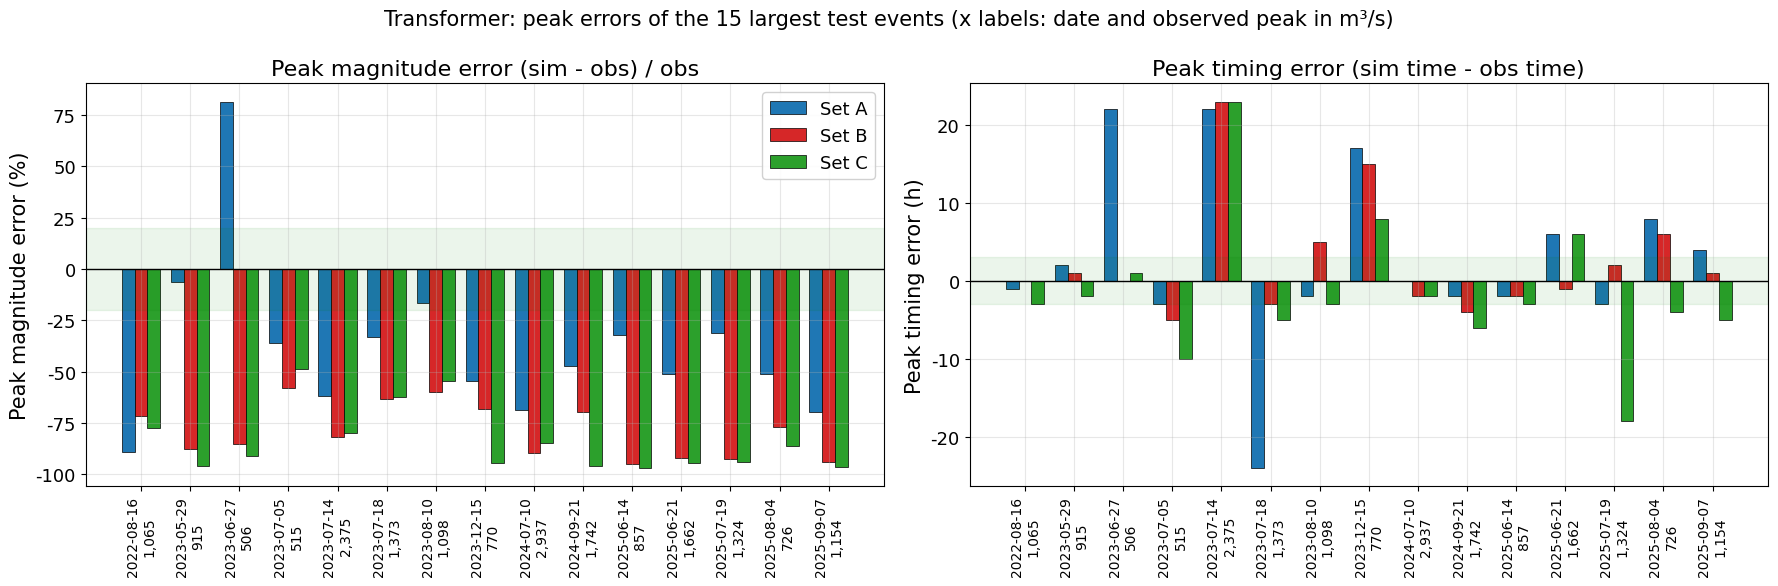

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
table = event_tables["A"]
x = np.arange(len(table))
w = 0.26
for i, s in enumerate(SETS):
    t = event_tables[s].reindex(table.index)
    axes[0].bar(x + (i - 1) * w, t["peak_error_pct"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
    axes[1].bar(x + (i - 1) * w, t["timing_error_h"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
labels = [f"{t:%Y-%m-%d}\n{v:,.0f}" for t, v in zip(table.index, table["obs_peak"])]
for ax, ylabel, title in zip(axes, ["Peak magnitude error (%)", "Peak timing error (h)"],
                             ["Peak magnitude error (sim - obs) / obs", "Peak timing error (sim time - obs time)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=10)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhspan(-20, 20, color="green", alpha=0.08)
axes[1].axhspan(-3, 3, color="green", alpha=0.08)
axes[0].legend(loc="best")
fig.suptitle(f"{NAME}: peak errors of the 15 largest test events (x labels: date and observed peak in m³/s)", fontsize=15)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_peak_errors")
plt.show()

## 7. 결과 해석

### 7.1 자동 요약 (지표 기반)

아래 글은 `common.narrative_for_run()` 이 지표 값으로부터 규칙적으로 생성한 요약입니다. 모든 모델 노트북에 같은 규칙을 적용하므로
모델 간 서술이 일관됩니다.

In [15]:
for s in SETS:
    display(Markdown(common.narrative_for_run(summaries[s])))

**Transformer / 입력세트 A (basin-average rainfall)**
- 테스트 기간 NSE 0.559, KGE 0.715, RMSE 57.5 m³/s, PBIAS -2.3%.
- 학습 NSE 0.596, 검증 NSE 0.532: 테스트 기간에서 성능이 다소 낮아지지만 큰 과적합 징후는 없습니다.
- 고유량 구간(FHV +0.0%)은 거의 편향 없이 재현되고, 저유량 구간(FLV +97.8%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -47.3%, 평균 절대 첨두오차 48.6%, 첨두 시각 오차 평균 +2.9 h (±3 h 이내 53%, 크기 ±20% 이내 13%).
- 학습: 48 epoch (early stopping), 최적 epoch 43, epoch당 평균 113 s, 총 학습시간 89.6 min, 파라미터 67,137개.

**Transformer / 입력세트 B (station rainfall (7 gauges))**
- 테스트 기간 NSE 0.169, KGE 0.104, RMSE 79.0 m³/s, PBIAS +43.5%.
- 학습 NSE(0.385)와 테스트 NSE의 차이가 0.22로 커서 **과적합 또는 기간 간 수문특성 차이**가 의심됩니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +43.5%)이 뚜렷합니다.
- 고유량 구간(FHV -44.9%)은 과소 재현되고, 저유량 구간(FLV +95.4%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -82.0%, 평균 절대 첨두오차 79.0%, 첨두 시각 오차 평균 +2.4 h (±3 h 이내 60%, 크기 ±20% 이내 0%).
- 학습: 36 epoch (early stopping), 최적 epoch 4, epoch당 평균 126 s, 총 학습시간 75.4 min, 파라미터 67,521개.

**Transformer / 입력세트 C (basin-average + station rainfall)**
- 테스트 기간 NSE 0.222, KGE 0.179, RMSE 76.4 m³/s, PBIAS -23.6%.
- 학습 NSE(0.386)와 테스트 NSE의 차이가 0.16로 커서 **과적합 또는 기간 간 수문특성 차이**가 의심됩니다.
- 전체 유량을 과소 추정하는 경향(PBIAS -23.6%)이 뚜렷합니다.
- 고유량 구간(FHV -53.1%)은 과소 재현되고, 저유량 구간(FLV +89.0%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -91.1%, 평균 절대 첨두오차 83.6%, 첨두 시각 오차 평균 -1.5 h (±3 h 이내 40%, 크기 ±20% 이내 0%).
- 학습: 45 epoch (early stopping), 최적 epoch 5, epoch당 평균 114 s, 총 학습시간 86.0 min, 파라미터 67,585개.

### 7.2 Transformer 의 결과 해석

**요약**: 테스트 NSE 0.56 (A), 0.17 (B), 0.22 (C) 로 **비교 모델 중 가장 낮다.** 결과 해석에서 중요한 점은 이것이 일반화 실패가 아니라
**학습 자체의 실패**라는 것이다: 학습 기간 NSE 도 0.60 / 0.39 / 0.39 에 그치고(LSTM 0.93), 세트 B·C 는 검증 loss 최소가 4–5 epoch 에서
나타난 뒤 더 이상 개선되지 않았다.

- **원인**: 모든 모델에 공통 적용한 학습 설정(Adam 1e-3, 워밍업 없음, batch 256, 720 단계 자기주의, 단일 유역 10만 샘플)은 트랜스포머에
  불리하다. 위치 인코딩을 더한 720개 토큰에서 "어느 시각의 강우가 지금 유량에 기여하는가"를 주의 가중치만으로 배우려면 더 긴 학습, 낮은
  학습률과 워밍업, 또는 짧은 창이 필요하다는 것이 일반적인 경험이며, 이 결과는 그 필요성을 그대로 보여 준다.
- **입력세트 효과**: 입력 차원이 1 → 7, 8 로 늘자 성능이 급락했다(A 0.56 → B 0.17). 임베딩(64차원)에 들어가는 입력이 많아질수록 학습이 더
  불안정해졌다.
- **홍수 첨두**: FHV −45 ~ −53% (B, C), 첨두 크기 오차 −47 ~ −91%, 첨두 시각 오차 5–8 h 로 홍수 재현이 불가능한 수준이다. 세트 A 조차
  첨두를 절반 가까이 놓친다.
- **비용**: 113–126 s/epoch 로 LSTM 의 약 14배이며 세 run 에 각각 1.5 시간 이상이 걸렸다.
- **시사점**: 본 비교의 "동일 설정" 원칙 아래서 순수 트랜스포머는 적합하지 않으며, 트랜스포머 계열은 **모델별 하이퍼파라미터 튜닝(future work)**
  없이는 순환 모델과 공정하게 비교하기 어렵다.


## 8. 요약

아래 표가 이 노트북의 최종 결과이며, `results/transformer_<set>/summary.json` 으로 저장되어 비교 노트북에서 사용됩니다.

In [16]:
summary_table = pd.DataFrame({
    f"Set {s}": {
        "parameters": summaries[s]["n_parameters"],
        "epochs trained": summaries[s]["epochs_trained"],
        "best epoch": summaries[s]["best_epoch"],
        "early stopped": summaries[s]["early_stopped"],
        "s / epoch": round(summaries[s]["epoch_time_mean_s"], 1),
        "training time (min)": round(summaries[s]["train_time_total_s"] / 60, 1),
        "test NSE": round(summaries[s]["metrics"]["test"]["NSE"], 3),
        "test KGE": round(summaries[s]["metrics"]["test"]["KGE"], 3),
        "test RMSE (m³/s)": round(summaries[s]["metrics"]["test"]["RMSE"], 1),
        "test PBIAS (%)": round(summaries[s]["metrics"]["test"]["PBIAS"], 1),
        "test FHV (%)": round(summaries[s]["metrics"]["test"]["FHV"], 1),
        "peak |error| mean (%)": round(summaries[s]["events_test"]["peak_abs_error_mean_pct"], 1),
        "peak |timing| mean (h)": round(summaries[s]["events_test"]["timing_abs_error_mean_h"], 1),
    } for s in SETS})
display(summary_table)
summary_table.to_csv(common.RESULTS_DIR / f"{MODEL}_summary_table.csv")

,Set A,Set B,Set C
parameters,67137,67521,67585
epochs trained,48,36,45
best epoch,43,4,5
early stopped,True,True,True
s / epoch,113.0,126.3,114.2
training time (min),89.6,75.4,86.0
test NSE,0.559,0.169,0.222
test KGE,0.715,0.104,0.179
test RMSE (m³/s),57.5,79.0,76.4
test PBIAS (%),-2.3,43.5,-23.6
